In [1]:
import massipipe.pipeline as mpi
import massipipe.processors as mpp
import massipipe.utils as mpu
import matplotlib.pyplot as plt
import importlib 
import numpy as np
import subprocess

In [2]:
# Paths
dataset_dir = '/home/mha114/data/seabee-minio/larvik/kongsbakkebukta/aerial/hsi/20230830/massimal_larvik_kongsbakkebukta_202308301328_hsi/'

In [3]:
pipeline = mpi.PipelineProcessor(dataset_dir)

16:42:40 INFO: File logging initialized.


In [4]:
# NOTE: Need to re-implement mosaicing using osgeo.gdal before mosaicing works 
# pipeline.run(geotiff_from_glint_corrected_reflectance=True,mosaic_geotiffs=False)

In [5]:
pipeline.config

{'grouping': 'larvik',
 'area': 'kongsbakkebukta',
 'datetime': '202308301328',
 'nfiles': 26,
 'organisation': 'UiT',
 'mosaic': True,
 'classify': False,
 'publish': False,
 'theme': 'Habitat',
 'spectrum_type': 'HSI',
 'creator_name': 'Martin H. Skjelvareid',
 'project': 'Massimal',
 'massipipe_options': {'create_products': {'radiance': True,
   'radiance_gc': True,
   'reflectance': True,
   'reflectance_gc': True},
  'create_mosaics': {'radiance': False,
   'radiance_gc': False,
   'reflectance': False,
   'reflectance_gc': False},
  'glint_correction': {'reference_image_numbers': [14, 15],
   'reference_image_ranges': [[1000, 2000, 0, 900], None],
   'reflectance_gc_method': 'flat_spec'}}}

In [6]:
hedley_glint_corrector = mpp.HedleyGlintCorrector()

In [8]:
reference_image_numbers = pipeline.config['massipipe_options']['glint_correction']['reference_image_numbers'] 
reference_image_paths = [pipeline.refl_im_paths[ind] for ind in reference_image_numbers]
reference_image_ranges = pipeline.config['massipipe_options']['glint_correction']['reference_image_ranges']
hedley_glint_corrector.fit_to_reference_images(reference_image_paths,
                                               reference_image_ranges=reference_image_ranges)


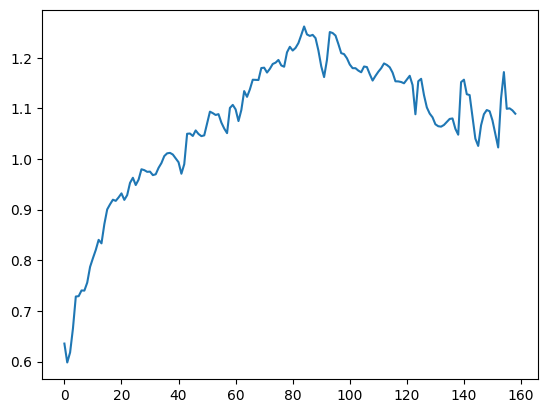

In [9]:
plt.plot(hedley_glint_corrector.b.T)

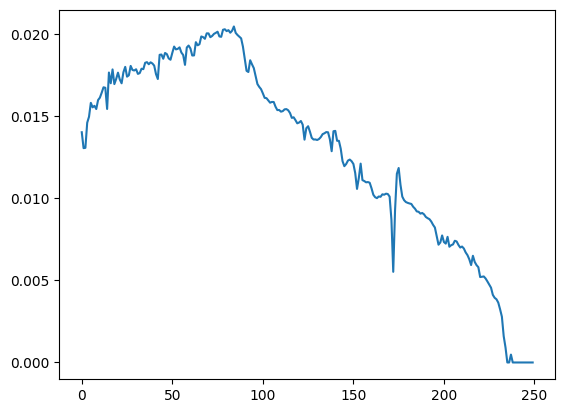

In [10]:
plt.plot(hedley_glint_corrector.dark_spec)

In [11]:
image,wl,metadata = mpu.read_envi(pipeline.refl_im_paths[14])

In [12]:
image_gc = hedley_glint_corrector.glint_correct_image(image)

In [13]:
image_gc.shape

(2000, 900, 159)

In [14]:
wl_vis = wl[hedley_glint_corrector.vis_ind]

In [15]:
image_rgb, wl_rgb = mpu.rgb_subset_from_hsi(image,wl)

In [16]:
image_gc_rgb,_ = mpu.rgb_subset_from_hsi(image_gc,wl_vis)

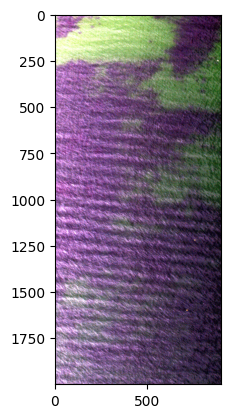

In [17]:
qlp = mpp.QuickLookProcessor()
plt.imshow(qlp.percentile_stretch_image(image_rgb))

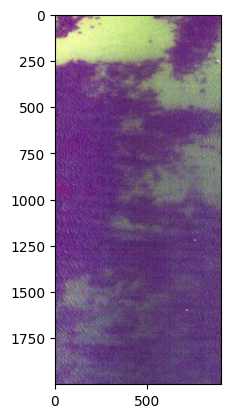

In [18]:
plt.imshow(qlp.percentile_stretch_image(image_gc_rgb))

In [19]:
image_flatspecgc,_,_ = mpu.read_envi(pipeline.refl_gc_im_paths[14])

In [20]:
image_fsgc_rgb,_ = mpu.rgb_subset_from_hsi(image_flatspecgc,wl)

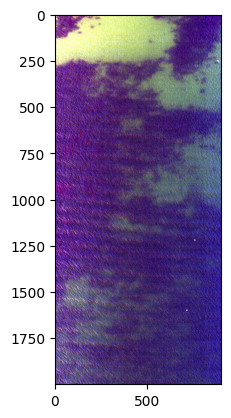

In [21]:
plt.imshow(qlp.percentile_stretch_image(image_fsgc_rgb))

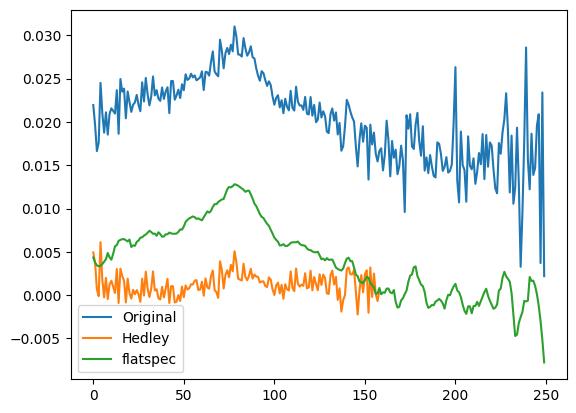

In [22]:
plt.plot(image[1500,200,:],label='Original')
plt.plot(image_gc[1500,200,:],label='Hedley')
plt.plot(image_flatspecgc[1500,200,:],label='flatspec')
plt.legend()

In [42]:
ref_image,_,_ = mpu.read_envi(pipeline.refl_im_paths[15])

In [43]:
dark_spec = np.percentile(ref_image.reshape((-1,ref_image.shape[-1])),2,axis=0)
dark_spec_1 = np.percentile(ref_image.reshape((-1,ref_image.shape[-1])),1,axis=0)

In [44]:
dark_spec.shape

(250,)

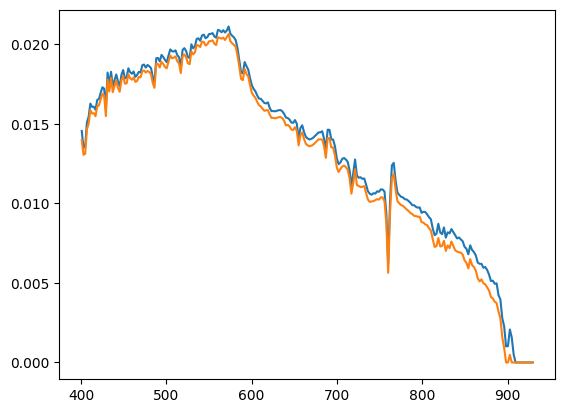

In [45]:
plt.plot(wl,dark_spec)
plt.plot(wl,dark_spec_1)

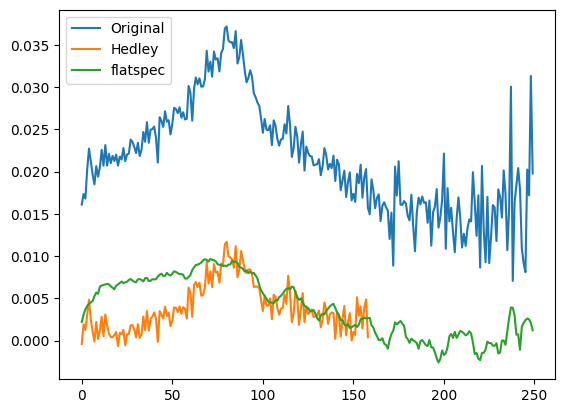

In [46]:
plt.plot(image[200,200,:],label='Original')
plt.plot(image_gc[200,200,:],label='Hedley')
plt.plot(image_flatspecgc[1000,200,:],label='flatspec')
plt.legend()


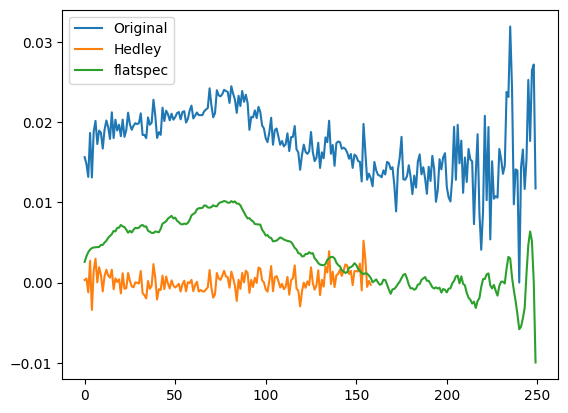

In [47]:
plt.plot(image[200,750,:],label='Original')
plt.plot(image_gc[200,750,:],label='Hedley')
plt.plot(image_flatspecgc[1000,750,:],label='flatspec')
plt.legend()

In [49]:
image_gc_filt = mpu.savitzky_golay_filter(image_gc)

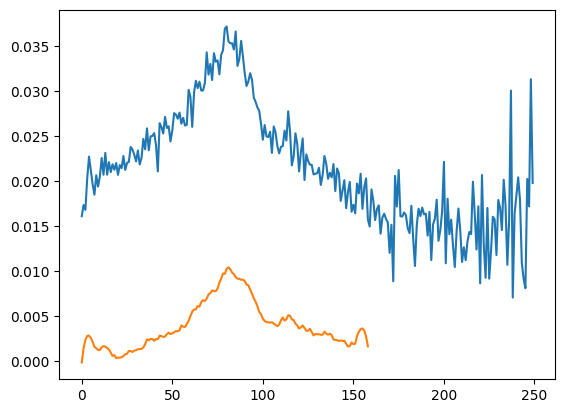

In [50]:
plt.plot(image[200,200,:],label='Original')
plt.plot(image_gc_filt[200,200,:],label='Hedley')